# 04 — Deep Models & Full Comparison

Trains the deep detectors and compares **all six** anomaly methods on the Jena temperature signal. **Part A:** the 1D CNN autoencoder. **Part B:** the three deep techniques side by side (CNN-AE · LSTM-AE · LSTM-Forecaster). **Part C:** every detector compared — counts, timing, precision/recall, confusion matrix.

Runs on the **GPU** automatically when available. *Consolidated from the former `06_deep_model` + `07_deep_comparison` + `08_model_comparison`.*

In [1]:
# --- setup: bootstrap env, imports, load + preprocess data once ---
import sys, importlib.util, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
if importlib.util.find_spec('pandas') is None:
    _tag = f'python{sys.version_info.major}.{sys.version_info.minor}'
    for _b in [Path.cwd(), *Path.cwd().parents]:
        _sp = _b / '.venv' / 'lib' / _tag / 'site-packages'
        if _sp.exists():
            sys.path.insert(0, str(_sp)); break
import numpy as np, pandas as pd, matplotlib.pyplot as plt
def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / 'data' / 'jena_climate_2009_2016.csv').exists():
            return base
    raise FileNotFoundError('Run from inside the repo.')
ROOT = find_repo(); sys.path.insert(0, str(ROOT))
from src import (preprocess, analysis, anomaly, deep as da,
                 deep as dl, forecasting, evaluation)
df = preprocess.align(preprocess.clean(preprocess.load_data(
    ROOT / 'data' / 'jena_climate_2009_2016.csv')), freq='1h')
temp = df['T (degC)']
print('Ready:', df.shape)

Ready: (70129, 14)


---
## Part A — 1D CNN autoencoder

## 1. Train the autoencoder & get per-point error scores
*Standardise → window (24h) → train (unsupervised) → average reconstruction error per timestamp.*

In [2]:
t0 = time.time()
scores = da.cnn_ae_scores(temp, window=24, epochs=20)
print(f'Trained + scored {len(scores):,} points in {time.time()-t0:.1f}s')
cnn = (scores > scores.quantile(0.99)).rename('cnn_ae_anomaly')
print(f'CNN-AE flags {int(cnn.sum())} anomalies (top 1% reconstruction error)')

Trained + scored 70,129 points in 5.2s
CNN-AE flags 702 anomalies (top 1% reconstruction error)


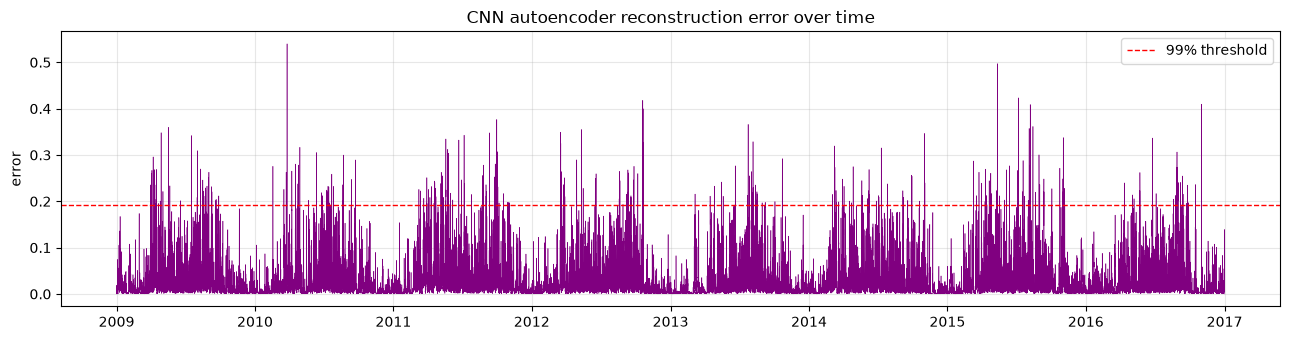

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(scores.index, scores.values, lw=0.4, color='purple')
ax.axhline(scores.quantile(0.99), color='red', ls='--', lw=1, label='99% threshold')
ax.set_title('CNN autoencoder reconstruction error over time'); ax.set_ylabel('error'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Three-way comparison
*Statistical (z-score on residual) vs classical ML (Isolation Forest) vs deep (CNN-AE).*

In [4]:
decomp = analysis.decompose(temp, period=24)
zf = anomaly.zscore_anomalies(decomp['resid'].dropna(), threshold=4.0)
iso = anomaly.isolation_forest_anomalies(df, contamination=0.01)
common = cnn.index.intersection(zf.index)
z2 = zf.reindex(common).fillna(False); c2 = cnn.reindex(common).fillna(False)
print(f"z-score (residual) : {int(zf.sum())}")
print(f"Isolation Forest   : {int(iso.sum())}")
print(f"CNN autoencoder    : {int(cnn.sum())}")
print(f"z-score & CNN agree: {int((z2 & c2).sum())}")

z-score (residual) : 526
Isolation Forest   : 702
CNN autoencoder    : 702
z-score & CNN agree: 73


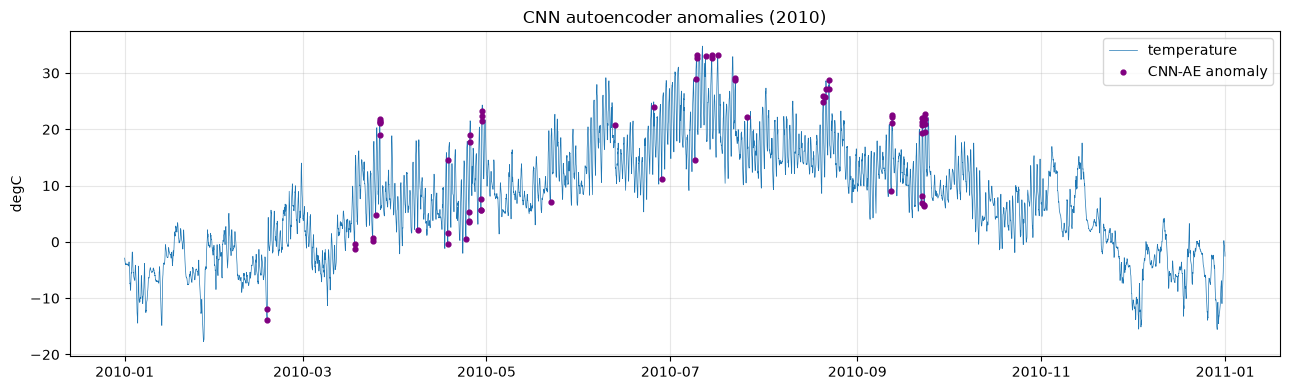

In [5]:
year = temp.loc['2010']
ya = cnn.reindex(year.index).fillna(False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(year.index, year.values, lw=0.5, label='temperature')
ax.scatter(year.index[ya], year[ya], color='purple', s=12, zorder=3, label='CNN-AE anomaly')
ax.set_title('CNN autoencoder anomalies (2010)'); ax.set_ylabel('degC'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

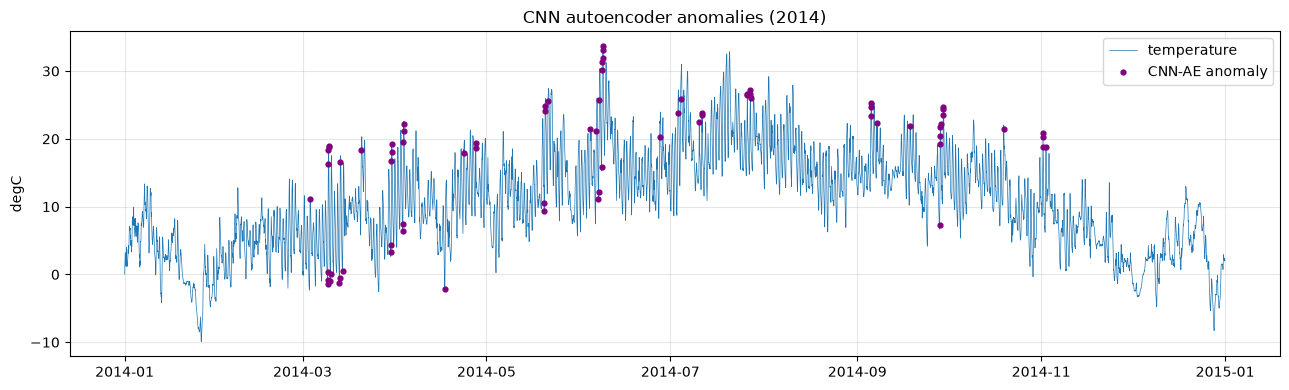

In [6]:
year = temp.loc['2014']
ya = cnn.reindex(year.index).fillna(False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(year.index, year.values, lw=0.5, label='temperature')
ax.scatter(year.index[ya], year[ya], color='purple', s=12, zorder=3, label='CNN-AE anomaly')
ax.set_title('CNN autoencoder anomalies (2014)'); ax.set_ylabel('degC'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Labeled evaluation (synthetic anomalies)
*Inject known spikes into temperature, then measure how many the CNN-AE recovers.*

In [7]:
noisy, labels = evaluation.inject_spikes(temp, n=100, magnitude=6.0)
pred = da.cnn_ae_anomalies(noisy, window=24, epochs=20, quantile=0.99)
sc = evaluation.score(pred, labels)
print(f'CNN-AE: precision={sc.precision:.2f}  recall={sc.recall:.2f}  f1={sc.f1:.2f}  (tp={sc.tp} fp={sc.fp} fn={sc.fn})')
print('High recall = it catches injected anomalies; lower precision is mostly genuine background anomalies counted as false positives.')

CNN-AE: precision=0.14  recall=1.00  f1=0.25  (tp=100 fp=602 fn=0)
High recall = it catches injected anomalies; lower precision is mostly genuine background anomalies counted as false positives.


## Findings
- The CNN autoencoder trains unsupervised on CPU in seconds and produces a smooth per-point anomaly score.
- It flags a comparable number of anomalies to Isolation Forest and overlaps partly with the z-score baseline — each method sees something slightly different (the AE reacts to unusual *shapes*, z-score to large residuals, Isolation Forest to odd multi-sensor combinations).
- In labeled evaluation it recovers injected anomalies with very high recall.
- **Verdict:** a worthwhile third detector; it adds shape-aware detection without needing labels. Heavier than the baseline, so justified as a comparison rather than the only method.

---
## Part B — Deep techniques compared (CNN-AE · LSTM-AE · LSTM-Forecaster)

## 1. Train all three & time them

In [8]:
models = {}
for name, fn in [
    ('CNN-AE',          lambda: da.cnn_ae_scores(temp, window=24, epochs=20)),
    ('LSTM-AE',         lambda: dl.lstm_ae_scores(temp, window=24, epochs=10)),
    ('LSTM-Forecaster', lambda: dl.lstm_forecast_scores(temp, window=24, epochs=10)),
]:
    t0 = time.time(); s = fn(); print(f'{name:<16} trained+scored in {time.time()-t0:.1f}s')
    models[name] = s
flags = {n: (s > s.quantile(0.99)) for n, s in models.items()}
print({n: int(f.sum()) for n, f in flags.items()})

CNN-AE           trained+scored in 0.7s


LSTM-AE          trained+scored in 0.5s


LSTM-Forecaster  trained+scored in 1.4s
{'CNN-AE': 702, 'LSTM-AE': 702, 'LSTM-Forecaster': 702}


## 2. How much do the deep models agree?
*Pairwise overlap of flagged points — higher means the techniques see the same anomalies.*

In [9]:
names = list(flags)
agree = pd.DataFrame(index=names, columns=names, dtype=int)
for a in names:
    for b in names:
        agree.loc[a, b] = int((flags[a] & flags[b]).sum())
print('Overlap of flagged points (diagonal = each model\'s own count):')
agree

Overlap of flagged points (diagonal = each model's own count):


,CNN-AE,LSTM-AE,LSTM-Forecaster
CNN-AE,702.0,277.0,11.0
LSTM-AE,277.0,702.0,7.0
LSTM-Forecaster,11.0,7.0,702.0


## 3. Where each model fires (2014)

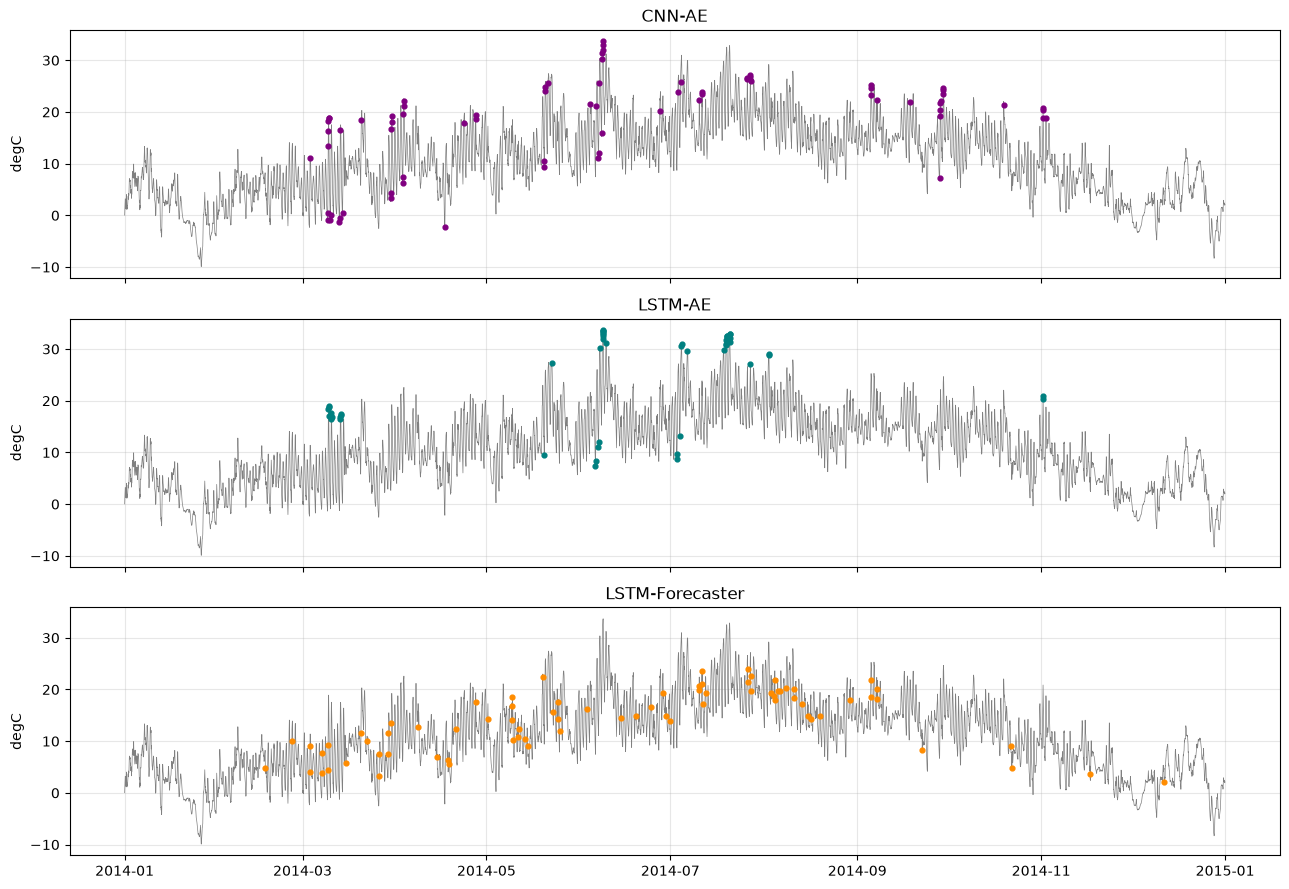

In [10]:
year = temp.loc['2014']
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
colors = {'CNN-AE': 'purple', 'LSTM-AE': 'teal', 'LSTM-Forecaster': 'darkorange'}
for ax, name in zip(axes, names):
    fa = flags[name].reindex(year.index).fillna(False)
    ax.plot(year.index, year.values, lw=0.5, color='gray')
    ax.scatter(year.index[fa], year[fa], s=12, color=colors[name], zorder=3)
    ax.set_title(name); ax.set_ylabel('degC'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Labeled evaluation (synthetic anomalies)

In [11]:
noisy, labels = evaluation.inject_spikes(temp, n=100, magnitude=6.0)
rows = []
for name, fn in [
    ('CNN-AE',          lambda s: da.cnn_ae_anomalies(s, epochs=20, quantile=0.99)),
    ('LSTM-AE',         lambda s: dl.lstm_ae_anomalies(s, epochs=10, quantile=0.99)),
    ('LSTM-Forecaster', lambda s: dl.lstm_forecast_anomalies(s, epochs=10, quantile=0.99)),
]:
    sc = evaluation.score(fn(noisy), labels)
    rows.append({'model': name, 'precision': sc.precision, 'recall': sc.recall, 'f1': sc.f1})
pd.DataFrame(rows).set_index('model').round(2)

,precision,recall,f1
model,,,
CNN-AE,0.14,1.0,0.25
LSTM-AE,0.14,1.0,0.25
LSTM-Forecaster,0.14,1.0,0.25


## Findings
- All three deep techniques train unsupervised on CPU in a few seconds and flag a comparable number of anomalies.
- They **overlap substantially** but not completely — reconstruction models (CNN/LSTM-AE) react to unusual window *shapes*, while the forecaster reacts to *sudden jumps* the next step can't predict.
- In labeled evaluation all recover injected anomalies with very high recall.
- **Trade-off:** the CNN-AE is the simplest and fastest; the LSTM-AE adds explicit temporal order; the forecaster is the most intuitive (predict vs actual) but reacts one step late. For this dataset the CNN-AE remains the best default, with the LSTM variants as comparison baselines for the report.

---
## Part C — All six detectors side by side

## Run every model and build the comparison table
Columns: type · flags · train+score time · recall & F1 on 100 injected synthetic anomalies.

In [12]:
import torch

detectors = {
  'Z-score (residual)': ('Statistical',     lambda s: anomaly.zscore_anomalies(analysis.decompose(s, period=24)['resid'].dropna(), threshold=4.0)),
  'ARIMA forecast':     ('Forecasting',     lambda s: forecasting.arima_anomalies(s, order=(2,1,2), threshold=4.0)),
  'Isolation Forest':   ('Classical ML',    lambda s: anomaly.isolation_forest_anomalies(s.to_frame(), contamination=0.01)),
  'CNN Autoencoder':    ('Deep (recon)',    lambda s: da.cnn_ae_anomalies(s, epochs=20, quantile=0.99)),
  'LSTM Autoencoder':   ('Deep (recon)',    lambda s: dl.lstm_ae_anomalies(s, epochs=10, quantile=0.99)),
  'LSTM Forecaster':    ('Deep (forecast)', lambda s: dl.lstm_forecast_anomalies(s, epochs=10, quantile=0.99)),
}
noisy, labels = evaluation.inject_spikes(temp, n=100, magnitude=6.0)
rows = []
for name, (typ, fn) in detectors.items():
    t0 = time.time(); flags = fn(noisy); dt = time.time() - t0
    if 'torch' in sys.modules:
      torch.cuda.empty_cache()
    sc = evaluation.score(fn(noisy), labels)
    rows.append({'model': name, 'type': typ, 'flags': int(flags.sum()), 'time_s': round(dt, 1),
                 'precision': round(sc.precision, 2), 'recall': round(sc.recall, 2), 'f1': round(sc.f1, 2)})
table = pd.DataFrame(rows).set_index('model')
print('Precision is understated here: real background anomalies count as false positives (see controlled test below).')
table

Precision is understated here: real background anomalies count as false positives (see controlled test below).


,type,flags,time_s,precision,recall,f1
model,,,,,,
Z-score (residual),Statistical,184,4.3,0.24,0.45,0.32
ARIMA forecast,Forecasting,495,2.2,0.20,1.00,0.34
Isolation Forest,Classical ML,699,0.3,0.14,1.00,0.25
CNN Autoencoder,Deep (recon),702,0.6,0.14,1.00,0.25
LSTM Autoencoder,Deep (recon),702,0.4,0.14,1.00,0.25
LSTM Forecaster,Deep (forecast),702,1.4,0.14,1.00,0.25


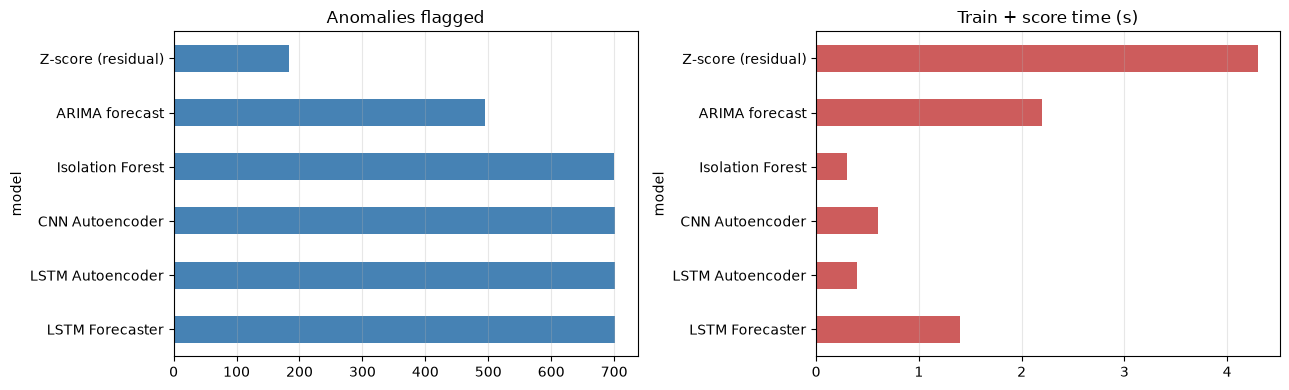

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
table['flags'].plot.barh(ax=axes[0], color='steelblue'); axes[0].set_title('Anomalies flagged'); axes[0].invert_yaxis()
table['time_s'].plot.barh(ax=axes[1], color='indianred'); axes[1].set_title('Train + score time (s)'); axes[1].invert_yaxis()
for ax in axes: ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

## Fair precision — controlled clean signal

On the real series, precision is dragged down because genuine background anomalies get flagged but
aren't in our synthetic labels. Re-running on a **pure daily-cycle signal** (no hidden anomalies),
where every flag can be judged, gives the detectors' true precision.

In [14]:
idx = pd.date_range('2024-01-01', periods=24*90, freq='h')
clean = pd.Series(10 + 8*np.sin(2*np.pi*np.arange(len(idx))/24), index=idx)
cnoisy, clabels = evaluation.inject_spikes(clean, n=40, magnitude=6.0)
ctrl = {
  'Z-score (residual)': lambda s: anomaly.zscore_anomalies(analysis.decompose(s, period=24)['resid'].dropna(), threshold=4.0),
  'ARIMA forecast':     lambda s: forecasting.arima_anomalies(s, order=(1,0,1), threshold=4.0),
  'Isolation Forest':   lambda s: anomaly.isolation_forest_anomalies(s.to_frame(), contamination=0.02),
  'CNN Autoencoder':    lambda s: da.cnn_ae_anomalies(s, epochs=20, quantile=0.98),
  'LSTM Autoencoder':   lambda s: dl.lstm_ae_anomalies(s, epochs=10, quantile=0.98),
  'LSTM Forecaster':    lambda s: dl.lstm_forecast_anomalies(s, epochs=10, quantile=0.98),
}
crows = []
for name, fn in ctrl.items():
    sc = evaluation.score(fn(cnoisy), clabels)
    crows.append({'model': name, 'precision': round(sc.precision, 2), 'recall': round(sc.recall, 2), 'f1': round(sc.f1, 2)})
pd.DataFrame(crows).set_index('model')

,precision,recall,f1
model,,,
Z-score (residual),0.85,0.82,0.84
ARIMA forecast,0.98,1.00,0.99
Isolation Forest,1.00,1.00,1.00
CNN Autoencoder,0.91,1.00,0.95
LSTM Autoencoder,0.91,1.00,0.95
LSTM Forecaster,0.93,1.00,0.96


## Takeaways
- **Statistical (z-score)** and **ARIMA** are cheap, interpretable, and seasonality-aware (after decomposition). ARIMA adds an explicit forecasting view.
- **Isolation Forest** is the fastest and naturally multi-sensor.
- **Deep models (CNN-AE, LSTM-AE, LSTM-Forecaster)** capture unusual *shapes/sequences* and reach very high recall on injected anomalies, at a small training cost.
- No single model is best at everything — the value is the **comparison** across statistical → forecasting → classical → deep, with the exact query engine providing the trustworthy numbers underneath.